# Notebook 3

In [1]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

### Degree Centrality

Identifies the most importante nodes in a network
- Directed network: degree
- Undirected network: in-degree and/or out-degree

Directed Network: 

```Centrailty(node) = degree(v) / (|all nodes| - 1)```

```0 <= Centrality <= 1```

###### # Example 1

In [2]:
g = nx.karate_club_graph()

In [3]:
g = nx.convert_node_labels_to_integers(g, first_label=1)

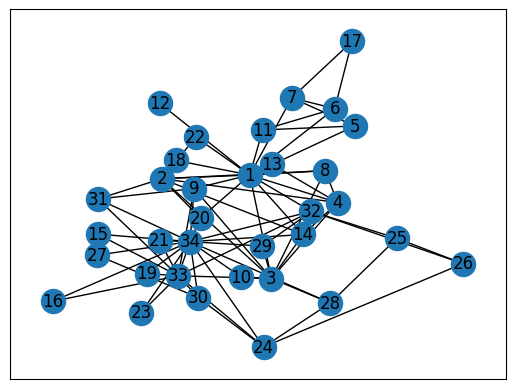

In [4]:
pos = nx.kamada_kawai_layout(g)
nx.draw_networkx(g, pos)

In [5]:
nx.center(g)

[1, 2, 3, 4, 9, 14, 20, 32]

In [6]:
nx.degree_centrality(g)[34] # 13/33

0.5151515151515151

In [7]:
nx.degree_centrality(g)[33] # 12/33

0.36363636363636365

###### # Example 2

In [8]:
gd = nx.MultiDiGraph()

In [9]:
e = [
        ('A', 'B'), ('A', 'E'), ('A', 'N'),
        ('B', 'C'), ('B', 'E'),
        ('C', 'A'), ('C', 'D'),
        ('D', 'B'), ('D', 'E'),
        ('E', 'D'), ('E', 'C'),
        ('F', 'G'),
        ('G', 'A'), ('G', 'J'),
        ('H', 'G'), ('H', 'I'),
        ('I', 'G'), ('I', 'F'), ('I', 'J'),
        ('J', 'F'), ('J', 'O'),
        ('K', 'L'), ('K', 'M'),
        ('L', 'M'),
        ('N', 'L'), ('N', 'O'),
        ('O', 'K'), ('O', 'L'),('O','J')
    ]

In [10]:
gd.add_edges_from(e)
gd

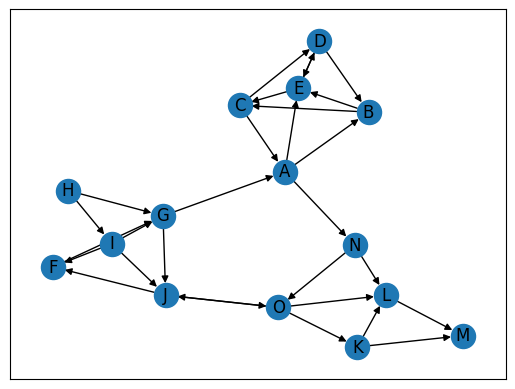

In [11]:
pos = nx.kamada_kawai_layout(gd)
nx.draw_networkx(gd, pos)

In [12]:
# IN-degree
i = nx.in_degree_centrality(gd)
# OUT-degree
o = nx.out_degree_centrality(gd)

In [13]:
i['A'], o['A']

(0.14285714285714285, 0.21428571428571427)

### Closenesse Centrality

Nodes that are important, will be close to other nodes

![closeness centrality](./3/ccentrality.png)

###### # Example 3

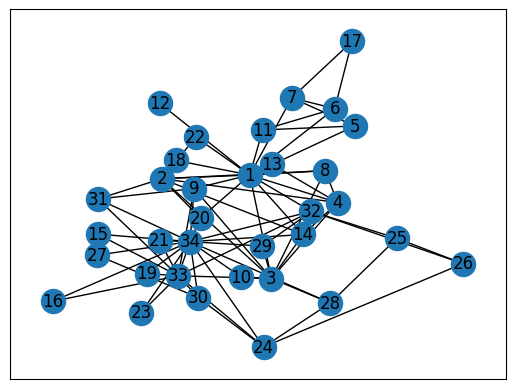

In [14]:
pos = nx.kamada_kawai_layout(g)
nx.draw_networkx(g, pos)

In [15]:
cc = nx.closeness_centrality(g)

In [16]:
cc[32]

0.5409836065573771

In [17]:
sum(nx.shortest_path_length(g, 32).values())

61

###### # Example 4

![disconnected](./3/disconnected.png)

In [18]:
nx.closeness_centrality(gd)

{'A': 0.32010582010582006,
 'B': 0.2700892857142857,
 'E': 0.27880184331797236,
 'N': 0.26190476190476186,
 'C': 0.2216117216117216,
 'D': 0.2216117216117216,
 'F': 0.2216117216117216,
 'G': 0.19206349206349205,
 'J': 0.2700892857142857,
 'H': 0.0,
 'I': 0.07142857142857142,
 'O': 0.28809523809523807,
 'K': 0.24489795918367344,
 'L': 0.32625482625482627,
 'M': 0.28}

![disconnected2](./3/disconnected2.png)

The nx.closeness_centrality() method is already normalized by

```( (n-1) / (|G|-1) )```

*There's **no** need to do it manually, like in the lecture!*

In [19]:
nx.closeness_centrality(gd)['L']

0.32625482625482627

### Betweenness Centrality

A node 'n' has high Betweenness Centrality if it appears a great number of times in the shortest paths between nodes 'u' and 'v'

![betweennes centrality](./3/beecentrality.png)

Note that we can either **include** or **exclude** the node 'v' as an **endpoint**

![betweennes centrality 2](./3/beecentrality02.png)

We consider Betweenness Centrality only for nodes who can be reached

###### # Example 5

In [20]:
g_noD = nx.DiGraph()

In [21]:
g_noD.add_edges_from([
    
    ('A', 'B'),
    ('B', 'C'),
    ('C', 'A'),
    ('D', 'B'),
    ('D', 'C')
    
])

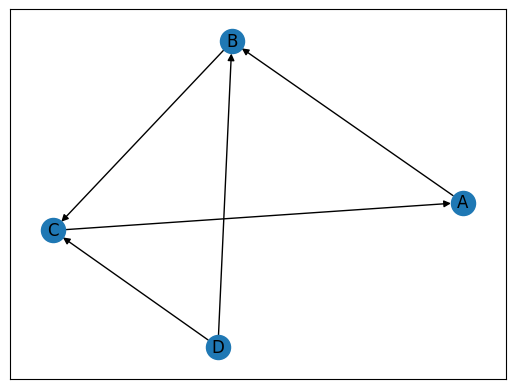

In [22]:
pos = nx.kamada_kawai_layout(g_noD)
nx.draw_networkx(g_noD, pos)

If we calculate the BetCentrality for node 'D', it would have us dividing by zero. Hence, we assume it as undefined.

###### # Example 6

In [23]:
g = nx.Graph()

In [24]:
g.add_edges_from(
    [
        ('A', 'B'), ('A', 'C'),
        ('B', 'C'),
        ('C', 'D'),
        ('D', 'E'),
        ('E', 'F'), ('E', 'G'),
        ('F', 'G')
    ]
)

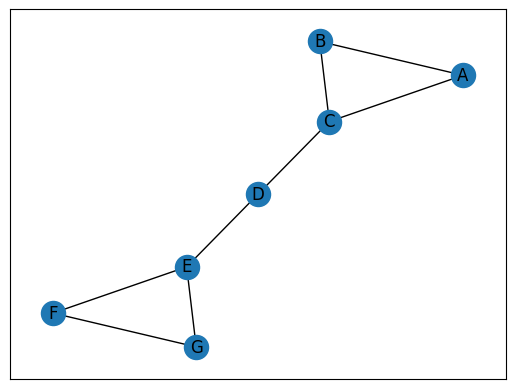

In [25]:
pos = nx.kamada_kawai_layout(g)
nx.draw_networkx(g, pos)

In [26]:
bcc = nx.betweenness_centrality(G=g, endpoints=False)
bcc

{'A': 0.0,
 'B': 0.0,
 'C': 0.5333333333333333,
 'D': 0.6,
 'E': 0.5333333333333333,
 'F': 0.0,
 'G': 0.0}

In [27]:
def maxKeyVal(x: dict):
    keys = list(x.keys())
    values = list(x.values())
    return keys[values.index(max(values))], max(list(x.values()))

def minKeyVal(x: dict):
    keys = list(x.keys())
    values = list(x.values())
    return keys[values.index(min(values))], min(list(x.values()))

In [28]:
maxKeyVal(bcc), minKeyVal(bcc)

(('D', 0.6), ('A', 0.0))

Normalization: BetCentrality values will be larger in graphs with many nodes.

- Undirected Graphs:
    
    ```1/2 * ((|N| - 1) * (|N| - 2))```

- Directed Graphs
    
    ```(|N| - 1) * (|N| - 2)```
    
nx.betweenness_centrality() method already has a 'normalized' parameter, True as default

###### # Example 7

Betweeness Centrality can be cost intensive

```O(|N|³)```

which leads us to calculate it using samples from the graph

In [29]:
g = nx.karate_club_graph()

In [30]:
g = nx.convert_node_labels_to_integers(g, first_label=1)

In [31]:
betCentrality = nx.betweenness_centrality(G=g, normalized=True, endpoints=False)

In [32]:
# Using (k = 10) samples
betCentrality_approx = nx.betweenness_centrality(G=g, normalized=True, endpoints=False, k=10)

In [33]:
from operator import itemgetter

In [34]:
# top 5 from bet
sorted(betCentrality.items(), key=itemgetter(1), reverse=True)[:6]

[(1, 0.43763528138528146),
 (34, 0.30407497594997596),
 (33, 0.145247113997114),
 (3, 0.14365680615680618),
 (32, 0.13827561327561325),
 (9, 0.05592682780182781)]

In [35]:
# top 5 from betCentrality_approx
sorted(betCentrality_approx.items(), key=itemgetter(1), reverse=True)[:6]

[(1, 0.4605623196248197),
 (34, 0.29498556998557),
 (33, 0.20837572150072153),
 (3, 0.13635416666666664),
 (32, 0.11000631313131312),
 (9, 0.06237012987012987)]

###### # Example 8

Compute the BetCentrality between two groups, source and target groups

In [36]:
s_nodes = [34, 33, 21, 30, 16, 27, 15, 23, 10]
t_nodes = [1, 4, 13, 11, 6, 12, 17, 7]

In [37]:
betCen_subset = nx.betweenness_centrality_subset(G=g,
                                                sources=s_nodes,
                                                targets=t_nodes,
                                                normalized=True)

In [38]:
# top 5 from betCen_subset
sorted(betCen_subset.items(), key=itemgetter(1), reverse=True)[:6]

[(1, 0.04899515993265994),
 (34, 0.028807419432419434),
 (3, 0.018368205868205867),
 (33, 0.01664712602212602),
 (9, 0.014519450456950456),
 (32, 0.014519450456950456)]

###### # Example 9

Use BetCentrality to find imoprtant edges

In [39]:
betCen_edges = nx.edge_betweenness_centrality(G=g, normalized=True)

In [40]:
# top 5 from betCen_edges
sorted(betCen_edges.items(), key=itemgetter(1), reverse=True)[:6]

[((1, 32), 0.1272599949070537),
 ((1, 7), 0.07813428401663695),
 ((1, 6), 0.07813428401663694),
 ((1, 3), 0.0777876807288572),
 ((1, 9), 0.07423959482783014),
 ((3, 33), 0.06898678663384543)]

Compute the BetCentrality between two edges groups, source and target groups

In [41]:
betCen_edges_subset = nx.edge_betweenness_centrality_subset(G=g,
                                                            sources=s_nodes,
                                                            targets=t_nodes,
                                                            normalized=True)

In [42]:
# top 5 from betCen_edges_subset
sorted(betCen_edges_subset.items(), key=itemgetter(1), reverse=True)[:6]

[((1, 9), 0.01366536513595337),
 ((1, 32), 0.01366536513595337),
 ((14, 34), 0.012207509266332794),
 ((1, 3), 0.01211343123107829),
 ((1, 6), 0.012032085561497326),
 ((1, 7), 0.012032085561497326)]

In [43]:
# top 5 from betCen_edges_subset
sorted(betCen_edges_subset.items(), key=itemgetter(1), reverse=True)[:6]

[((1, 9), 0.01366536513595337),
 ((1, 32), 0.01366536513595337),
 ((14, 34), 0.012207509266332794),
 ((1, 3), 0.01211343123107829),
 ((1, 6), 0.012032085561497326),
 ((1, 7), 0.012032085561497326)]